# Importação de Módulos

In [95]:
import pandas as pd
import matplotlib.pyplot as plt

## Set de Variaveis

In [96]:
CSV_PATH = "csv/googleplaystore.csv"

In [97]:
def installs_to_int(value):
    value = value.replace(",", "")
    if not value[-1].isdigit():
        value = value[:-1]
    return int(value)

def money_to_int(value):
    if value[0] == "$":
        value = value[1:]
    return float(value)

def to_mb(value):
    if not value[0].isdigit():
        return None
    if not value[-1].isdigit():
        return float(value[:-1])
    return float(value)


## Tratamento de Dados

In [98]:
df = pd.read_csv(CSV_PATH)
df.drop_duplicates()
df = df.query("Rating <= 5.0")
df.Reviews = df.Reviews.apply(lambda x: int(x))
df.Installs = df.Installs.apply(lambda x: installs_to_int(x))
df.Price = df.Price.apply(lambda x: money_to_int(x))
df.sort_values(by="App", ascending=True).head(100)
df = df.groupby(["App","Category","Size","Installs","Type","Price","Rating","Content Rating","Genres","Last Updated", "Current Ver", "Android Ver"], as_index=False).sum()
df.head()

,App,Category,Size,Installs,Type,Price,Rating,Content Rating,Genres,Last Updated,Current Ver,Android Ver,Reviews
0,+Download 4 Instagram Twitter,SOCIAL,22M,1000000,Free,0.0,4.5,Everyone,Social,"August 2, 2018",5.03,4.1 and up,40467
1,- Free Comics - Comic Apps,COMICS,9.1M,10000,Free,0.0,3.5,Mature 17+,Comics,"July 13, 2018",5.0.12,5.0 and up,115
2,.R,TOOLS,203k,10000,Free,0.0,4.5,Everyone,Tools,"September 16, 2014",1.1.06,1.5 and up,259
3,/u/app,COMMUNICATION,53M,10000,Free,0.0,4.7,Mature 17+,Communication,"July 3, 2018",4.2.4,4.1 and up,573
4,058.ba,NEWS_AND_MAGAZINES,14M,100,Free,0.0,4.4,Everyone,News & Magazines,"July 6, 2018",1.0,4.2 and up,27


## Top 5 apps por numero de Instalação

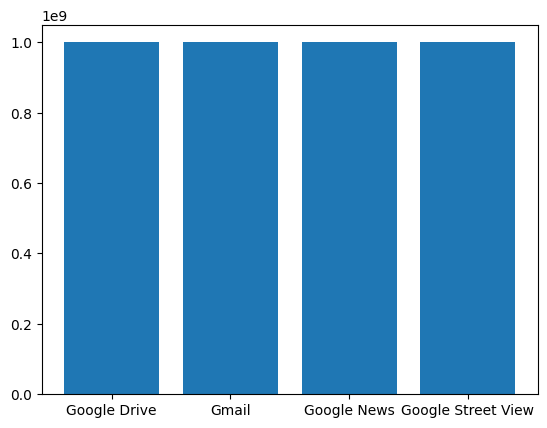

In [99]:
top5 = df.sort_values(by="Installs", ascending=False).head(5)

plt.bar(data=top5, x="App", height="Installs")

plt.show()

## Categorias de Aplicativos

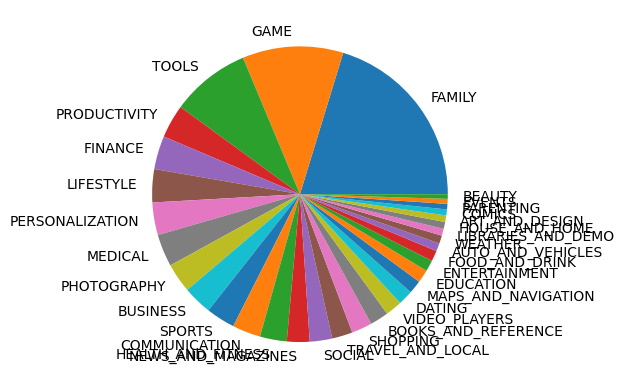

In [148]:
app_categories = df.groupby("Category", as_index=False).count().sort_values(by="App", ascending=False)

plt.pie(data=app_categories, x="App", labels="Category")

plt.show()

## App mais Caro

In [101]:
most_price_app = df.sort_values(by="Price", ascending=False).head(1)

most_price_app.head()

,App,Category,Size,Installs,Type,Price,Rating,Content Rating,Genres,Last Updated,Current Ver,Android Ver,Reviews
4418,I'm Rich - Trump Edition,LIFESTYLE,7.3M,10000,Paid,400.0,3.6,Everyone,Lifestyle,"May 3, 2018",1.0.1,4.1 and up,275


## Apps com Restrição de Idade +17

In [102]:
all_mature = df.query("`Content Rating` == 'Mature 17+'")

all_mature.head()

,App,Category,Size,Installs,Type,Price,Rating,Content Rating,Genres,Last Updated,Current Ver,Android Ver,Reviews
1,- Free Comics - Comic Apps,COMICS,9.1M,10000,Free,0.0,3.5,Mature 17+,Comics,"July 13, 2018",5.0.12,5.0 and up,115
3,/u/app,COMMUNICATION,53M,10000,Free,0.0,4.7,Mature 17+,Communication,"July 3, 2018",4.2.4,4.1 and up,573
12,"100000+ Messages - DP, Status, Jokes & GIF 2018",LIFESTYLE,3.8M,10000,Free,0.0,3.7,Mature 17+,Lifestyle,"December 29, 2017",DPSTATUS1.0.1,4.0.3 and up,121
33,211:CK Lite,GAME,39M,10,Free,0.0,4.3,Mature 17+,Action,"September 22, 2017",1.0,4.1 and up,3
36,"2Date Dating App, Love and matching",DATING,8.1M,500000,Free,0.0,4.4,Mature 17+,Dating,"July 26, 2018",4.813,4.0.3 and up,41605


## 10 Apps com mais Reviews

In [103]:
top_10_apps_reviews = df.sort_values(by="Reviews", ascending=False).head(10)

top_10_apps_reviews.head()

,App,Category,Size,Installs,Type,Price,Rating,Content Rating,Genres,Last Updated,Current Ver,Android Ver,Reviews
4483,Instagram,SOCIAL,Varies with device,1000000000,Free,0.0,4.5,Teen,Social,"July 31, 2018",Varies with device,Varies with device,266241989
7774,WhatsApp Messenger,COMMUNICATION,Varies with device,1000000000,Free,0.0,4.4,Everyone,Communication,"August 3, 2018",Varies with device,Varies with device,207348304
5162,Messenger – Text and Video Chat for Free,COMMUNICATION,Varies with device,1000000000,Free,0.0,4.0,Everyone,Communication,"August 1, 2018",Varies with device,Varies with device,169932272
6902,Subway Surfers,GAME,76M,1000000000,Free,0.0,4.5,Everyone 10+,Arcade,"July 12, 2018",1.90.0,4.1 and up,166331958
3472,Facebook,SOCIAL,Varies with device,1000000000,Free,0.0,4.1,Teen,Social,"August 3, 2018",Varies with device,Varies with device,156286514


## Média do tamanho dos Apps

In [176]:
size_mean = df["Size"].apply(lambda x: to_mb(x)).mean()

print(f"Media do tamanho dos aplicativos: {size_mean: .2f}")

Media do tamanho dos aplicativos:  37.40


## Quantidade de Apps Pagos e Gratuitos

In [152]:
count_of_types = df.groupby("Type", as_index=False).count()[["Type","App"]]

count_of_types.head(100)

,Type,App
0,Free,7707
1,Paid,604


## Gráfico Sobre a Quantidade de apps pagos e gratuitos

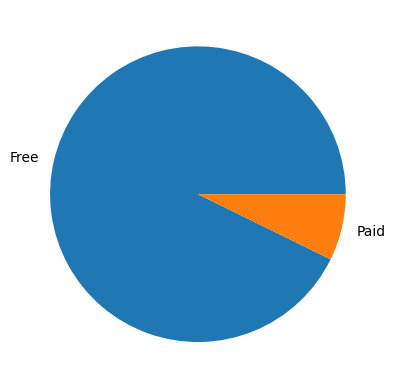

In [151]:
plt.pie(data=count_of_types, x="App", labels="Type")

plt.show()

## Gráfico sobre 10 aplicativos com mais Reviews

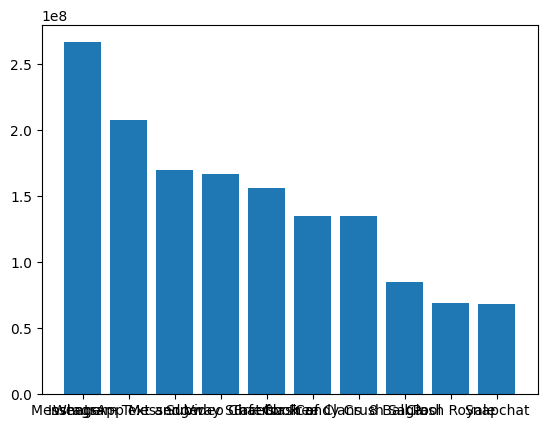

In [177]:
plt.bar(data=top_10_apps_reviews, x="App" ,height="Reviews")

plt.show()